# Day 33 — Practice ANSWERS
### Drawing the Best Line

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

| Part | What it asks you to do | How many |
|---|---|---|
| **A** | Work it out — pen and paper | 8 |
| **B** | Find the mistake in a short program | 4 |
| **C** | Write the code yourself | 5 |
| **D** | Challenge | 2 |

### How to work

**Part A needs no computer.** The numbers are chosen so the arithmetic is clean. Work it
out in the margin, *then* run the cell to check.

The three questions to keep asking:

- Is a straight line even the **right shape** for this data?
- Is the number I am predicting **inside the range** I actually saw?
- What do the errors look like — random, or a **pattern**?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

import warnings
warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (8, 3.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("ready")

ready


---
# Part A — Work it out

Eight questions. No computer needed for most of them.

**The two formulas:**

```
slope      =  Σ (x − x̄)(y − ȳ)  ÷  Σ (x − x̄)²
intercept  =  ȳ  −  slope × x̄
```

### A1 · Find the best line by hand

Five students: practice problems solved per week, and their quiz score out of 50.

| problems | 2 | 4 | 6 | 8 | 10 |
|---|---|---|---|---|---|
| **score** | 19 | 27 | 33 | 37 | 44 |

Work out the slope and the intercept. Build the table of `x − x̄`, `y − ȳ`, their product,
and `(x − x̄)²` first.

In [2]:
x = np.array([2., 4, 6, 8, 10])
y = np.array([19., 27, 33, 37, 44])

t = pd.DataFrame({"x": x, "y": y, "x − x̄": x - x.mean(), "y − ȳ": y - y.mean()})
t["product"] = t["x − x̄"] * t["y − ȳ"]
t["(x − x̄)²"] = t["x − x̄"] ** 2
print("x̄ =", x.mean(), "   ȳ =", y.mean())
t

x̄ = 6.0    ȳ = 32.0


,x,y,x − x̄,y − ȳ,product,(x − x̄)²
0,2.0,19.0,-4.0,-13.0,52.0,16.0
1,4.0,27.0,-2.0,-5.0,10.0,4.0
2,6.0,33.0,0.0,1.0,0.0,0.0
3,8.0,37.0,2.0,5.0,10.0,4.0
4,10.0,44.0,4.0,12.0,48.0,16.0


x̄ = **6**,  ȳ = **32**

| x | y | x − 6 | y − 32 | product | (x − 6)² |
|---|---|---|---|---|---|
| 2 | 19 | −4 | −13 | 52 | 16 |
| 4 | 27 | −2 | −5 | 10 | 4 |
| 6 | 33 | 0 | +1 | 0 | 0 |
| 8 | 37 | +2 | +5 | 10 | 4 |
| 10 | 44 | +4 | +12 | 48 | 16 |
| | | | **totals** | **120** | **40** |

**slope = 120 ÷ 40 = 3**

**intercept = 32 − 3 × 6 = 14**

### `score = 3 × problems + 14`

Say it out loud: **each extra practice problem a week is worth about 3 marks.**

In [3]:
slope = t["product"].sum() / t["(x − x̄)²"].sum()
intercept = y.mean() - slope * x.mean()

print("slope     =", t["product"].sum(), "/", t["(x − x̄)²"].sum(), "=", slope)
print("intercept =", y.mean(), "−", slope, "×", x.mean(), "=", intercept)
print()
print("sklearn:", LinearRegression().fit(x.reshape(-1, 1), y).coef_[0],
      LinearRegression().fit(x.reshape(-1, 1), y).intercept_)

slope     = 120.0 / 40.0 = 3.0
intercept = 32.0 − 3.0 × 6.0 = 14.0

sklearn: 3.0 14.0


### A2 · Total squared error

Using your line from A1, work out the error on each student and the total squared error.

In [4]:
# fill in your line here, then run
pred = 3 * x + 14
err = y - pred

print("the line says :", pred)
print("they got      :", y)
print("errors        :", err)
print()
print("errors added  :", err.sum())
print("squares added :", (err ** 2).sum())

the line says : [20. 26. 32. 38. 44.]
they got      : [19. 27. 33. 37. 44.]
errors        : [-1.  1.  1. -1.  0.]

errors added  : 0.0
squares added : 4.0


| x | actual | line | error | error² |
|---|---|---|---|---|
| 2 | 19 | 20 | −1 | 1 |
| 4 | 27 | 26 | +1 | 1 |
| 6 | 33 | 32 | +1 | 1 |
| 8 | 37 | 38 | −1 | 1 |
| 10 | 44 | 44 | 0 | 0 |
| | | **total** | **0** | **4** |

**Total squared error = 4.**

And notice the errors add to exactly **0**. That is not luck — it is true of the best
line for *every* dataset. It is also exactly why adding them is a useless score.

### A3 · Beat it, if you can

Try `slope = 4, intercept = 8` and `slope = 2, intercept = 20`. Both pass through the
average point (6, 32). Do either of them beat a total squared error of 4?

In [5]:
def total_squared_error(slope, intercept):
    return float(((y - (slope * x + intercept)) ** 2).sum())

for sl, ic in [(2, 20), (3, 14), (4, 8)]:
    print(f"score = {sl} × problems + {ic:<3}  ->  total squared error = {total_squared_error(sl, ic):>5.0f}")

score = 2 × problems + 20   ->  total squared error =    44
score = 3 × problems + 14   ->  total squared error =     4
score = 4 × problems + 8    ->  total squared error =    44


```
score = 2 × problems + 20   ->  total squared error =    44
score = 3 × problems + 14   ->  total squared error =     4
score = 4 × problems + 8    ->  total squared error =    44
```

**Neither comes close.** And look at the symmetry: slope 2 and slope 4 give *exactly the
same* score, 44. They are the same distance from 3 on either side.

That is the bowl from the lecture, measured. The formula did not guess — it landed on the
one point where no nudge in either direction helps.

### A4 · What does the intercept mean here?

Your line says `score = 3 × problems + 14`.

- What does 14 mean in plain English?
- Should you quote it to anybody?

**14 means: a student who solves zero practice problems is predicted to score 14 out of 50.**

**Should you quote it? No.**

Look at the data: the fewest problems anybody solved was **2**. Nobody in this group
solved zero. So 14 is the line being extended into territory it never saw — an
extrapolation, exactly like asking about 25 hours of study in the lecture.

It might be roughly right. It might be badly wrong, because a student who does *no*
practice at all may behave completely differently from one who does a little.
**You have no evidence either way.**

**The habit:** before quoting the intercept, check whether `x = 0` is inside your data. If
it is not, the intercept is a mathematical artefact that holds the line in place, not a
finding.

### A5 · R² by hand

Using total squared error 4 from A2, work out R² — no `sklearn`.

*Reminder:* R² = 1 − (your line's total squared error ÷ the flat average's total squared error)

In [6]:
flat = np.full_like(y, y.mean())
print("if we guessed", y.mean(), "every time, the squared errors would be:")
print("   ", (y - flat) ** 2)
print("    total:", ((y - flat) ** 2).sum())

if we guessed 32.0 every time, the squared errors would be:
    [169.  25.   1.  25. 144.]
    total: 364.0


Guessing the average, 32, every time:

errors are −13, −5, +1, +5, +12 → squared: 169, 25, 1, 25, 144 → **total 364**

**R² = 1 − (4 ÷ 364) = 1 − 0.01099 = 0.9890**

The line removed **98.9%** of the error that always guessing 32 would have left.

Check it:

```python
r2_score(y, 3*x + 14)   # 0.989010989010989
```

A number worth holding on to: R² is **not** "how good the line is" in the abstract. It is
"how much better than guessing the average", and nothing else.

### A6 · One step of gradient descent

Start at slope 0 and intercept 0 on the A1 data. With a learning rate of 0.01, work out
the slope and intercept after **one** step.

*Reminder:*
```
slope nudge      =  (2/n) × Σ (error × x)        where error = line − actual
intercept nudge  =  (2/n) × Σ (error)
new value        =  old value − rate × nudge
```

In [7]:
e = (0 * x + 0) - y          # line minus actual, starting from a flat line at zero
print("errors (line − actual):", e)
print("Σ(error × x) =", (e * x).sum())
print("Σ(error)     =", e.sum())

errors (line − actual): [-19. -27. -33. -37. -44.]
Σ(error × x) = -1080.0
Σ(error)     = -160.0


Starting line predicts 0 for everybody, so the errors are −19, −27, −33, −37, −44.

- Σ(error × x) = −38 − 108 − 198 − 296 − 440 = **−1080**
- Σ(error) = **−160**

**slope nudge = (2/5) × (−1080) = −432**
**intercept nudge = (2/5) × (−160) = −64**

**new slope = 0 − 0.01 × (−432) = 4.32**
**new intercept = 0 − 0.01 × (−64) = 0.64**

Both nudges are negative, which is the method saying *both numbers are too small*.

Total squared error before: 5,484. After one step: **221.7**. One step, and it fell by **96%**.

In [8]:
rate = 0.01
slope_nudge     = (2/5) * (e * x).sum()
intercept_nudge = (2/5) * e.sum()

new_slope     = 0 - rate * slope_nudge
new_intercept = 0 - rate * intercept_nudge

print("slope nudge     :", slope_nudge)
print("intercept nudge :", intercept_nudge)
print("new slope       :", new_slope)
print("new intercept   :", new_intercept)
print()
print("total squared error before:", total_squared_error(0, 0))
print("total squared error after :", round(total_squared_error(new_slope, new_intercept), 1))

slope nudge     : -432.0
intercept nudge : -64.0
new slope       : 4.32
new intercept   : 0.64

total squared error before: 5484.0
total squared error after : 221.7


### A7 · Which of these should NOT be modelled with a straight line?

For each, say yes or no and why.

| | The situation |
|---|---|
| a | Flat area in square feet → monthly rent |
| b | Hours of study → exam mark, where marks are capped at 100 and most students already score 85+ |
| c | Age of a car → its resale price |
| d | Number of people in a restaurant → the noise level |

| | Line? | Why |
|---|---|---|
| a | **Yes** | Rent really does rise roughly steadily with area, over a normal range |
| b | **No** | There is a **ceiling**. Near 100 the relationship must flatten, and a line cannot flatten |
| c | **Not really** | Cars lose a big chunk of value in year one and then decline slowly — a curve, not a line |
| d | **No** | Noise is measured in decibels, which are **logarithmic**. Doubling the people does not double the number |

**(b) is the one from the lecture**, in disguise. Any time the thing you are predicting has
a hard floor or ceiling that the data gets close to, a straight line will be wrong at the
edges — and the errors will tell you so.

**The habit:** before you fit, ask *"could this relationship keep going forever in both
directions?"* If the answer is no, and your data reaches the limit, a line is the wrong
shape.

### A8 · Two models, one dataset

Two students fit a line to the same 200 rows.

| | R² on the rows it studied | R² on hidden rows |
|---|---|---|
| **Priya** | 0.71 | 0.69 |
| **Arjun** | 0.98 | 0.34 |

What happened in each case, and whose model would you ship?

**Priya's model learned the pattern.** 0.71 and 0.69 — the tiny gap means what it found on
the rows it studied also holds on rows it has never seen. That is what a working model
looks like.

**Arjun's model memorised the rows.** 0.98 on the rows it studied, then collapse to 0.34.
It learned the specific 140 rows it was shown, including their noise, and that knowledge
is worthless on anybody else.

**Ship Priya's**, without hesitation. 0.69 that you can trust beats 0.98 that you cannot.

### But here is the thing worth noticing

A **simple linear regression cannot do what Arjun's model did.** It has two numbers to
adjust. You cannot memorise 140 rows with two numbers.

So Arjun was not fitting a straight line. He had either a far more flexible model (a deep
tree, as on Day 31), or a huge pile of columns (as on Day 32), or he leaked something.

**The gap between the two scores is the diagnostic.** Small gap: the model is learning.
Large gap: it is memorising, and you need a simpler model or more rows.

---
# Part B — Find the mistake

Four short programs. Each one runs cleanly and reports something misleading.

### B1 · "R² is 0.83, so we are done"

In [9]:
rng = np.random.default_rng(401)
n = 90
bx = np.linspace(1, 20, n) + rng.normal(0, 0.2, n)      # weeks on the training programme
by = (12*np.log(bx) + 18 + rng.normal(0, 3, n)).round(1)  # fitness score

model = LinearRegression().fit(bx.reshape(-1, 1), by)
print("slope :", round(model.coef_[0], 3))
print("R²    :", round(model.score(bx.reshape(-1, 1), by), 4))

slope : 1.454
R²    : 0.8344


**The problem:** nobody looked at the data. R² of 0.83 is respectable, so the analyst
stopped — and missed that the relationship is a **curve**, not a line.

**The fix:** plot the scatter, and plot the errors against the input.

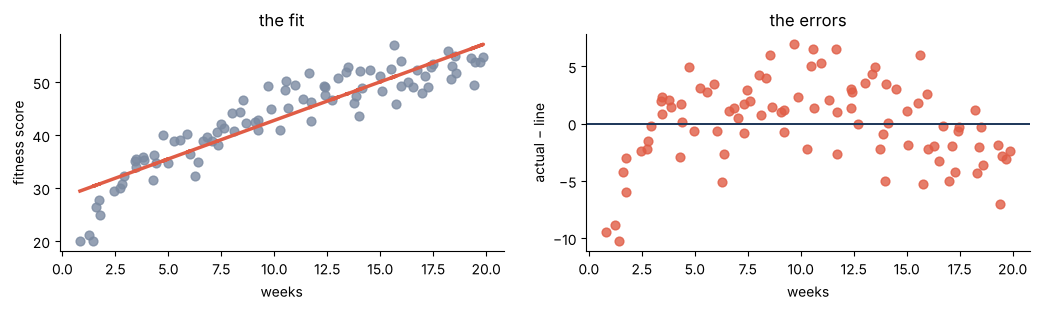

average error, by slice:
   weeks   0 to 5  :   -1.82   (20 people)
   weeks   5 to 10 :   +1.60   (23 people)
   weeks  10 to 15 :   +1.87   (22 people)
   weeks  15 to 21 :   -1.67   (25 people)


In [10]:
pred = model.predict(bx.reshape(-1, 1))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2))
axes[0].scatter(bx, by, s=40, color="#7B8AA1", alpha=0.8)
axes[0].plot(bx, pred, color="#E05C45", lw=2.5)
axes[0].set_title("the fit")
axes[0].set_xlabel("weeks"); axes[0].set_ylabel("fitness score")

axes[1].axhline(0, color="#1B3558", lw=1.4)
axes[1].scatter(bx, by - pred, s=40, color="#E05C45", alpha=0.8)
axes[1].set_title("the errors")
axes[1].set_xlabel("weeks"); axes[1].set_ylabel("actual − line")
plt.tight_layout(); plt.show()

print("average error, by slice:")
for lo, hi in [(0, 5), (5, 10), (10, 15), (15, 21)]:
    k = (bx >= lo) & (bx < hi)
    print(f"   weeks {lo:>3} to {hi:<3}:  {(by - pred)[k].mean():+6.2f}   ({k.sum()} people)")

```
weeks   0 to 5  :  -1.82   (20 people)
weeks   5 to 10 :  +1.60   (23 people)
weeks  10 to 15 :  +1.87   (22 people)
weeks  15 to 21 :  -1.67   (25 people)
```

**Low, high, high, low.** The errors are not scattered randomly — they swing in a clear
arc, which is the signature of a straight line drawn through a curve.

The programme gives big gains in the first few weeks and then levels off. A straight line
cannot level off, so it must under-predict at both ends and over-predict in the middle.

**R² never told you any of this.** 0.83 is a perfectly respectable number, and it was
hiding a model that is systematically wrong for everybody in their first five weeks and
everybody past week fifteen.

### B2 · The flat-pricing model

In [11]:
rng = np.random.default_rng(402)
area = rng.uniform(400, 1400, 70).round(0)
rent = (3000 + 21*area + rng.normal(0, 2200, 70)).round(0)

model = LinearRegression().fit(area.reshape(-1, 1), rent)

print(f"rent = {model.coef_[0]:.1f} × area + {model.intercept_:.0f}")
print()
print(f"a 5,000 sqft penthouse would rent for ₹{model.predict([[5000]])[0]:,.0f}")
print(f"an empty plot (0 sqft) would rent for ₹{model.intercept_:,.0f}")

rent = 21.1 × area + 2629

a 5,000 sqft penthouse would rent for ₹107,890
an empty plot (0 sqft) would rent for ₹2,629


**Two mistakes, both the same mistake.**

The flats in the data run from **416 to 1,392 square feet**. The program then asks the
line about:

- **5,000 sqft** — three and a half times bigger than anything it has ever seen
- **0 sqft** — the intercept, which is also outside the data

The line answers both without hesitation, because a line always will. Neither answer is
supported by a single row of evidence.

**The fix:** record your minimum and maximum, and refuse to predict outside them.

In [12]:
lo, hi = area.min(), area.max()
print(f"the data covers {lo:.0f} to {hi:.0f} sqft")
print()
for a in [500, 900, 1300, 2000, 5000]:
    inside = "inside the data" if lo <= a <= hi else "OUTSIDE — do not quote this"
    print(f"  {a:>5} sqft  ->  ₹{model.predict([[a]])[0]:>9,.0f}   ({inside})")

the data covers 416 to 1392 sqft

    500 sqft  ->  ₹   13,155   (inside the data)
    900 sqft  ->  ₹   21,576   (inside the data)
   1300 sqft  ->  ₹   29,997   (inside the data)
   2000 sqft  ->  ₹   44,734   (OUTSIDE — do not quote this)
   5000 sqft  ->  ₹  107,890   (OUTSIDE — do not quote this)


```
  500 sqft  ->  ₹ 13,155   (inside the data)
  900 sqft  ->  ₹ 21,576   (inside the data)
 1300 sqft  ->  ₹ 29,997   (inside the data)
 2000 sqft  ->  ₹ 44,733   (OUTSIDE — do not quote this)
 5000 sqft  ->  ₹107,890   (OUTSIDE — do not quote this)
```

Inside the range the model is genuinely useful. Outside it, you are extending a pencil
mark off the edge of the page.

**And the ₹2,629 intercept?** It is not "what an empty plot rents for". It is simply the
number the line needs in order to pass through the middle of the data. It has no meaning
on its own.

### B3 · "Our model scores 0.88"

In [13]:
X_train, X_hidden, y_train, y_hidden = train_test_split(
    area.reshape(-1, 1), rent, test_size=0.3, random_state=0)

model = LinearRegression().fit(X_train, y_train)

print("score:", round(model.score(X_train, y_train), 4))     # <-- look here

score: 0.8794


**The problem:** the split was done correctly, and then thrown away. The model was scored
on `X_train` — the very rows it learned from.

This is marking your own homework. The number is not wrong, it is just **not the number
anybody wants**: it tells you how well the model remembers, not how well it predicts.

**The fix:** score on `X_hidden`. That is the entire reason you split.

In [14]:
print("scored on the rows it studied :", round(model.score(X_train, y_train), 4))
print("scored on the hidden rows     :", round(model.score(X_hidden, y_hidden), 4))
print("the gap                       :", round(model.score(X_train, y_train)
                                               - model.score(X_hidden, y_hidden), 4))

scored on the rows it studied : 0.8794
scored on the hidden rows     : 0.7757
the gap                       : 0.1037


```
scored on the rows it studied : 0.8794
scored on the hidden rows     : 0.7757
the gap                       : 0.1037
```

The honest number is **0.776**, not 0.879. Reporting 0.88 would have overstated the model
by about ten points.

### Now the interesting part

A gap of **0.10** is larger than you would expect from a straight line. In the lecture the
gap was 0.017.

It is not overfitting — two numbers cannot memorise 49 rows. It is simply that 49 training
rows is not many, so *which* 49 you happened to get matters. Change `random_state` and
the gap will move around a lot.

**That is worth knowing in itself:** with small data, a single train/test split is a noisy
measurement. The fix is cross-validation, which is Day 36.

### B4 · One typo, and the model falls over

In [15]:
rng = np.random.default_rng(403)
hours = np.append(rng.uniform(1, 10, 40).round(1), 9.8)
score = np.append((30 + 5*hours[:40] + rng.normal(0, 3, 40)).round(0), 15.0)
#                                   the last student studied 9.8 hours and "scored 15"  ^^^^

model = LinearRegression().fit(hours.reshape(-1, 1), score)
print("slope :", round(model.coef_[0], 3))
print("R²    :", round(model.score(hours.reshape(-1, 1), score), 4))

slope : 4.153
R²    : 0.5


**The problem:** the last row says a student who studied 9.8 hours scored 15 — far below
everybody who studied even half as much. It is almost certainly a data-entry error.

**And least squares is especially vulnerable to it.** Remember why: errors are **squared**.
That single point is about 30 marks off the true line, so it contributes 900 to the total
— more than all forty genuine students put together. The line has no choice but to bend
towards it.

**The fix:** plot first, investigate the outlier, and only then decide whether to keep it.

with the bad row   : slope 4.153  R² 0.5
without the bad row: slope 5.096  R² 0.949


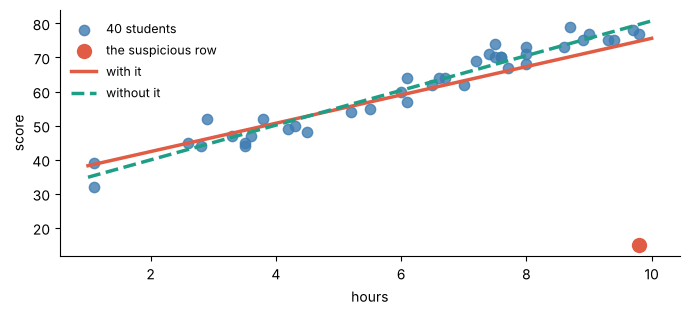

In [16]:
clean_model = LinearRegression().fit(hours[:40].reshape(-1, 1), score[:40])

print("with the bad row   : slope", round(model.coef_[0], 3),
      " R²", round(model.score(hours.reshape(-1, 1), score), 4))
print("without the bad row: slope", round(clean_model.coef_[0], 3),
      " R²", round(clean_model.score(hours[:40].reshape(-1, 1), score[:40]), 4))

plt.scatter(hours[:40], score[:40], s=55, color="#3E7CB1", alpha=0.8, label="40 students")
plt.scatter([hours[40]], [score[40]], s=170, color="#E05C45", zorder=6,
            edgecolor="white", lw=2, label="the suspicious row")
g = np.linspace(1, 10, 40)
plt.plot(g, model.predict(g.reshape(-1, 1)), color="#E05C45", lw=2.5, label="with it")
plt.plot(g, clean_model.predict(g.reshape(-1, 1)), color="#1F9E86", lw=2.5, ls="--",
         label="without it")
plt.legend(frameon=False, fontsize=9)
plt.xlabel("hours"); plt.ylabel("score")
plt.show()

```
with the bad row   : slope 4.153   R² 0.5000
without the bad row: slope 5.096   R² 0.9490
```

**One row out of forty-one.** It cut R² almost in half and pulled the slope down by 0.94 —
nearly a fifth of its true value.

### What to actually do

**Do not just delete it.** Deleting points because they are inconvenient is how people
fool themselves. In order:

1. **Go back to the source.** Was it typed wrong? Is it a different unit? Did the student
   sit a different paper?
2. If it is **genuinely wrong**, remove it and say so in your write-up.
3. If it is **genuinely real**, keep it — and report both numbers, because your reader
   deserves to know one point is driving the result.

And always plot the scatter first. This one is visible in half a second.

---
# Part C — Write the code

Five tasks on one dataset.

In [17]:
# ---------------------------------------------------------------
# 120 delivery riders. Run this once — C1 to C5 all use `riders`.
# ---------------------------------------------------------------
rng = np.random.default_rng(3301)
N = 120

experience = rng.uniform(1, 48, N).round(0)                        # months on the job
per_day = (6 + 0.22*experience + rng.normal(0, 1.5, N)).clip(2, None).round(1)

riders = pd.DataFrame({"experience_months": experience,
                       "deliveries_per_day": per_day})
riders.head()

,experience_months,deliveries_per_day
0,23.0,10.7
1,25.0,8.5
2,21.0,10.2
3,7.0,7.6
4,43.0,15.3


### C1 · Look before you fit

Draw the scatter plot. Before fitting anything, write one sentence: does a straight line
look like the right shape here?

In [18]:
# your code here

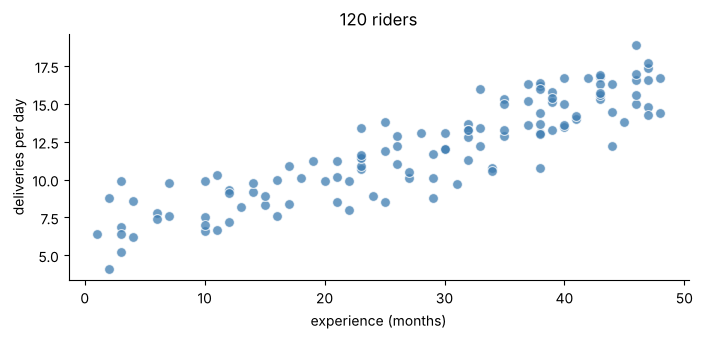

In [19]:
plt.scatter(riders.experience_months, riders.deliveries_per_day,
            s=50, color="#3E7CB1", alpha=0.75, edgecolor="white", lw=0.8)
plt.xlabel("experience (months)")
plt.ylabel("deliveries per day")
plt.title("120 riders")
plt.show()

**Yes, a line looks right.** The points form a band that rises steadily from left to
right, with roughly the same amount of scatter all the way across. There is no curve, no
levelling off, and no single point sitting far away from the rest.

**That sentence is Step 1 of the five-step recipe,** and it is the one people skip. It
costs ten seconds and it is the only thing that would have saved B1.

### C2 · Fit it, and say what the two numbers mean

Fit a `LinearRegression` on all 120 riders. Print the slope and intercept, then write
**one sentence each** saying what they mean — in words a delivery manager would
understand.

In [20]:
# your code here

In [21]:
X = riders[["experience_months"]]        # a TABLE, not a flat list
y = riders["deliveries_per_day"]

model = LinearRegression().fit(X, y)

print(f"deliveries = {model.coef_[0]:.4f} × months + {model.intercept_:.4f}")
print()
print(f"slope     {model.coef_[0]:.4f}")
print(f"intercept {model.intercept_:.4f}")
print()
print(f"experience in this data runs from {experience.min():.0f} to {experience.max():.0f} months")

deliveries = 0.2151 × months + 5.9793

slope     0.2151
intercept 5.9793

experience in this data runs from 1 to 48 months


```
deliveries = 0.2151 × months + 5.9793
```

**The slope, 0.2151:** *"Every extra month of experience is worth about 0.22 more
deliveries a day."*

Better still, scale it to something a manager can act on: **a full year of experience is
worth about 2.6 extra deliveries a day** (0.2151 × 12).

**The intercept, 5.98:** *"A brand-new rider with zero months of experience would do about
6 deliveries a day."*

And this time you **can** nearly quote it — experience starts at 1 month, so zero is only
just outside the data. Still say "about 6 on their first day", not "exactly 5.98".

### C3 · Score it honestly

Split the riders, fit on the training rows, and report:

- R² on the rows it studied, and on the hidden rows
- the average miss, in deliveries, on the hidden rows
- how that compares with just guessing the average for everybody

In [22]:
# your code here

In [23]:
X_train, X_hidden, y_train, y_hidden = train_test_split(X, y, test_size=0.3, random_state=0)

m = LinearRegression().fit(X_train, y_train)
guesses = m.predict(X_hidden)

print(f"R² on the rows it studied : {m.score(X_train, y_train):.4f}")
print(f"R² on the hidden rows     : {m.score(X_hidden, y_hidden):.4f}")
print(f"the gap                   : {m.score(X_train, y_train) - m.score(X_hidden, y_hidden):+.4f}")
print()
print(f"average miss on hidden rows : {mean_absolute_error(y_hidden, guesses):.3f} deliveries")

# the do-nothing baseline: always guess the training average
flat = np.full(len(y_hidden), y_train.mean())
print(f"average miss if we always guessed {y_train.mean():.2f} : "
      f"{mean_absolute_error(y_hidden, flat):.3f} deliveries")

R² on the rows it studied : 0.7941
R² on the hidden rows     : 0.7968
the gap                   : -0.0027

average miss on hidden rows : 1.183 deliveries
average miss if we always guessed 11.98 : 2.832 deliveries


```
R² on the rows it studied : 0.7941
R² on the hidden rows     : 0.7968
the gap                   : -0.0027

average miss on hidden rows : 1.183 deliveries
average miss if we always guessed 11.98 : 2.832 deliveries
```

**The gap is essentially zero** — and it even came out slightly *negative*, meaning the
model did marginally better on rows it had never seen.

That is not a mistake and it is not impossible. With only two numbers to adjust, the model
cannot memorise anything, so both scores are measuring the same thing; the small
difference is just which rows landed in which pile.

**Always report the baseline.** "Average miss 1.18" means nothing on its own. "Average
miss 1.18, against 2.83 for guessing the average" says the model **cut the error by 58%**
— and that is a sentence a manager can use.

### C4 · Check the errors

Plot the errors on the hidden rows against experience. Does the line fit, or is it the
wrong shape? Back your answer with the average error in four slices of the data.

In [24]:
# your code here

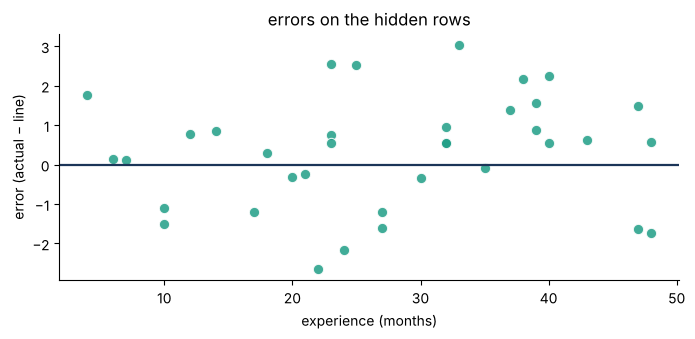

average error, by slice:
   months   0 to 12 :  -0.123   (5 riders)
   months  12 to 24 :  +0.136   (10 riders)
   months  24 to 36 :  +0.221   (10 riders)
   months  36 to 49 :  +0.740   (11 riders)


In [25]:
resid = y_hidden - guesses
h = X_hidden["experience_months"]

plt.axhline(0, color="#1B3558", lw=1.6)
plt.scatter(h, resid, s=55, color="#1F9E86", alpha=0.85, edgecolor="white", lw=0.8)
plt.xlabel("experience (months)"); plt.ylabel("error (actual − line)")
plt.title("errors on the hidden rows")
plt.show()

print("average error, by slice:")
for lo, hi in [(0, 12), (12, 24), (24, 36), (36, 49)]:
    k = (h >= lo) & (h < hi)
    print(f"   months {lo:>3} to {hi:<3}:  {resid[k].mean():+6.3f}   ({k.sum()} riders)")

```
months   0 to 12 :  -0.123   ( 5 riders)
months  12 to 24 :  +0.136   (10 riders)
months  24 to 36 :  +0.221   (10 riders)
months  36 to 49 :  +0.740   (11 riders)
```

**The line fits** — but this is a good example of why you must think about sample size
before you read a pattern into anything.

The first three slices sit within ±0.23 of zero, which is tiny next to an average miss of
1.18. The last one, **+0.74**, looks like it might be drifting upward.

**Is it real?** Two reasons to doubt it:

1. Those slices hold **5 to 11 riders each**. The standard error on a mean of 11 values
   with a spread of about 1.5 is roughly 0.45 — so +0.74 is well inside the range you
   would get from pure chance.
2. **Run the same slices on all 120 riders** and the apparent drift disappears:

```
months   0 to 12 : +0.273   (19 riders)
months  12 to 24 : -0.086   (26 riders)
months  24 to 36 : -0.390   (31 riders)
months  36 to 49 : +0.208   (44 riders)
```

No trend at all. The +0.74 was an artefact of looking at 11 riders.

Compare both with B1, where the slices went **−1.82, +1.60, +1.87, −1.67** on 20+ people
each. *That* was a shape. This is noise.

**The lesson:** a residual plot on a small hidden set will always show something. Before
you act on it, check whether the slice is big enough to mean anything — and look at the
full data.

### C5 · Answer three questions from management

Using your model, and refusing where you should:

1. A rider has been with us **18 months**. How many deliveries a day should we expect?
2. If we keep a rider an extra **year**, what do we gain?
3. What about a rider with **10 years** (120 months) of experience?

In [26]:
# your code here

In [27]:
full = LinearRegression().fit(X, y)
lo, hi = experience.min(), experience.max()
print(f"our data covers {lo:.0f} to {hi:.0f} months\n")

# 1
print(f"1.  18 months  ->  {full.predict([[18]])[0]:.2f} deliveries a day   (inside the data)")

# 2
print(f"2.  an extra 12 months is worth {full.coef_[0] * 12:.2f} more deliveries a day")

# 3
print(f"3.  120 months is {hi:.0f}-month data extended {120/hi:.1f}x — REFUSE.")
print(f"    (the line would say {full.predict([[120]])[0]:.2f}, which is not evidence)")

our data covers 1 to 48 months

1.  18 months  ->  9.85 deliveries a day   (inside the data)
2.  an extra 12 months is worth 2.58 more deliveries a day
3.  120 months is 48-month data extended 2.5x — REFUSE.
    (the line would say 31.79, which is not evidence)


**1. 18 months → about 9.85 deliveries a day.** Safely inside the data (1 to 48 months), so
this is a real prediction. Quote it as "about 10 a day", not 9.85 — the average miss is
1.16, so the extra decimals are fiction.

**2. An extra year is worth about 2.6 more deliveries a day.** This is the slope × 12, and
it is the most useful sentence the model produces. A manager can do something with it.

**3. Refuse.** Our oldest rider has 48 months. 120 months is **two and a half times**
beyond anything observed. The line would say 31.79 deliveries a day — and the busiest
rider we have ever recorded, at any experience level, does **18.9**. The model is
projecting someone **68% faster than the best person in the dataset**, on the strength of
no evidence whatsoever.

The honest answer is: *"We have no data on riders past four years, so I cannot tell you.
If that matters, let us go and find some."*

### Why refusing is the right professional answer

It is tempting to give the number with a caveat. Don't. The number will be remembered and
the caveat will not. **"I don't know, and here is what we'd need to find out"** is a
stronger answer than a confident 31.79.

---
# Part D — Challenge

Two tasks. Both are marked.

### D1 · Build least squares from scratch

Write **two** functions that find the best line, using no scikit-learn at all.

1. `fit_formula(x, y)` — uses the formula from the lecture. Returns `(slope, intercept)`.
2. `fit_descent(x, y, rate, steps)` — uses gradient descent. Returns `(slope, intercept)`.

Then prove all three agree — your two functions and `LinearRegression` — on the five
students from the lecture.

**Marks are for:**
- both functions working on any `x` and `y`, not just this dataset
- `fit_descent` reporting its progress so a reader can see it converging
- a clear demonstration that all three land in the same place

In [28]:
hours = np.array([1., 2, 3, 4, 5])
marks = np.array([34., 44, 47, 58, 67])

In [29]:
# your two functions here

In [30]:
def fit_formula(x, y):
    """The exact answer, in one calculation."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    dx = x - x.mean()
    dy = y - y.mean()
    slope = (dx * dy).sum() / (dx ** 2).sum()
    intercept = y.mean() - slope * x.mean()
    return slope, intercept


def fit_descent(x, y, rate=0.03, steps=3000, report=(1, 10, 100, 1000, 3000)):
    """The same answer, walked to one step at a time."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    n = len(x)
    slope = intercept = 0.0

    for step in range(1, steps + 1):
        error = (slope * x + intercept) - y            # line MINUS actual
        slope     -= rate * (2/n) * (error * x).sum()
        intercept -= rate * (2/n) * error.sum()
        if step in report:
            sse = float((((slope * x + intercept) - y) ** 2).sum())
            print(f"   step {step:>5}:  slope {slope:>7.3f}   intercept {intercept:>7.3f}"
                  f"   error {sse:>9.2f}")

    return slope, intercept

In [31]:
print("gradient descent, converging:")
d_slope, d_intercept = fit_descent(hours, marks)

f_slope, f_intercept = fit_formula(hours, marks)
sk = LinearRegression().fit(hours.reshape(-1, 1), marks)

print()
print(f"{'method':<22}{'slope':>12}{'intercept':>13}")
print("-" * 47)
print(f"{'my formula':<22}{f_slope:>12.6f}{f_intercept:>13.6f}")
print(f"{'my gradient descent':<22}{d_slope:>12.6f}{d_intercept:>13.6f}")
print(f"{'sklearn':<22}{sk.coef_[0]:>12.6f}{sk.intercept_:>13.6f}")

gradient descent, converging:
   step     1:  slope   9.960   intercept   3.000   error   1517.89
   step    10:  slope  13.525   intercept   6.052   error    376.16
   step   100:  slope  10.207   intercept  18.030   error     71.80
   step  1000:  slope   8.000   intercept  25.999   error     14.00
   step  3000:  slope   8.000   intercept  26.000   error     14.00

method                       slope    intercept
-----------------------------------------------
my formula                8.000000    26.000000
my gradient descent       8.000000    26.000000
sklearn                   8.000000    26.000000


In [32]:
# and prove it on a dataset none of us has seen, to show the functions are general
rng = np.random.default_rng(99)
tx = rng.uniform(0, 50, 200)
ty = 7.3 - 1.85*tx + rng.normal(0, 12, 200)          # a NEGATIVE slope this time

mine = fit_formula(tx, ty)
theirs = LinearRegression().fit(tx.reshape(-1, 1), ty)

print("on 200 random rows with a negative slope:")
print(f"   mine    : slope {mine[0]:.8f}  intercept {mine[1]:.8f}")
print(f"   sklearn : slope {theirs.coef_[0]:.8f}  intercept {theirs.intercept_:.8f}")
print(f"   difference: {abs(mine[0] - theirs.coef_[0]):.2e} and {abs(mine[1] - theirs.intercept_):.2e}")

on 200 random rows with a negative slope:
   mine    : slope -1.81833591  intercept 6.02681697
   sklearn : slope -1.81833591  intercept 6.02681697
   difference: 8.88e-16 and 2.13e-14


### The result

```
gradient descent, converging:
   step     1:  slope   9.960   intercept   3.000   error   1517.90
   step    10:  slope  13.525   intercept   6.052   error    376.16
   step   100:  slope  10.207   intercept  18.035   error     71.76
   step  1000:  slope   8.000   intercept  25.999   error     14.00
   step  3000:  slope   8.000   intercept  26.000   error     14.00

method                      slope    intercept
-----------------------------------------------
my formula               8.000000    26.000000
my gradient descent      8.000000    26.000000
sklearn                  8.000000    26.000000
```

**All three identical to six decimal places.** And on the 200-row test with a negative
slope (−1.81833591), the formula matches scikit-learn to **8.9e-16 on the slope and
2.1e-14 on the intercept** — which is floating-point noise, not disagreement.

### The three things that actually earn the marks

**1. Signs.** In `fit_descent` the error is `(line − actual)`, the opposite of the
reporting convention. Get this backwards and the slope runs away to infinity instead of
settling. The safest habit: write the loop, run five steps, and check the error is going
**down**. If it is going up, flip the sign.

**2. The functions are general.** They take any `x` and `y` — note the negative slope in
the test. A function that only works on the dataset you wrote it for is not a function,
it is a calculation.

**3. The convergence report.** Printing a few steps is what turns "trust me" into
evidence. A reader can see 1518 → 357 → 72 → 14 and know it worked.

### And one honest observation

`fit_formula` is exact and instant. `fit_descent` needs about a thousand steps to match
it, and a learning rate you had to choose.

So for a straight line the formula wins outright. **Gradient descent is still the more
important of the two**, because it is the only one that still exists when your model has
a million numbers instead of two.

### D2 · An R² of 0.93. Prove the claim is worthless.

A startup's marketing head sends this to the board:

> *"We fitted a regression of revenue against ad spend across our last 36 months. **R² is
> 0.93** — the relationship could not be clearer. Every ₹1,000 we put into advertising
> returns **₹7,735** in revenue. I am therefore requesting a budget of **₹500,000** for
> next month, which the model projects will deliver **₹3.9 million** in revenue."*

The regression is correctly fitted. There is no bug in the code.

**Your tasks:**

1. Run it and confirm the numbers.
2. Find **two separate reasons** the conclusion does not follow. They are different kinds
   of mistake.
3. Prove each one with evidence from the data.
4. Write three or four sentences you could send back to the board.

*Hints, in increasing order of giving it away: look at the ratio of the two columns · look
at what else is in the table · look at the range.*

In [33]:
rng = np.random.default_rng(5150)
n = 36                                                  # three years of months

month   = np.arange(n)
revenue = (420000 + 9500*month                          # the company is growing
           + 95000*np.sin(2*np.pi*(month % 12)/12 - 0.8)   # and it is seasonal
           + rng.normal(0, 38000, n)).round(0)

# the marketing team sets each month's budget from what they expect to sell
ad_spend = (0.12*revenue + rng.normal(0, 4000, n)).round(0)

books = pd.DataFrame({"month": month, "ad_spend": ad_spend, "revenue": revenue})
books.head(8)

,month,ad_spend,revenue
0,0,46176.0,404441.0
1,1,46659.0,393300.0
2,2,62230.0,542750.0
3,3,67747.0,548867.0
4,4,60714.0,488828.0
5,5,61265.0,587688.0
6,6,64272.0,536986.0
7,7,60158.0,524521.0


In [34]:
claim = LinearRegression().fit(books[["ad_spend"]], books["revenue"])

print(f"R²                      : {claim.score(books[['ad_spend']], books['revenue']):.4f}")
print(f"every ₹1 of ads returns : ₹{claim.coef_[0]:.3f}")
print(f"so ₹1,000 returns       : ₹{claim.coef_[0]*1000:,.0f}")
print(f"spend ₹500,000 and get  : ₹{claim.predict([[500000]])[0]:,.0f}")

R²                      : 0.9287
every ₹1 of ads returns : ₹7.735
so ₹1,000 returns       : ₹7,735
spend ₹500,000 and get  : ₹3,913,559


In [35]:
# your investigation here

In [36]:
# ---- REASON 1 --------------------------------------------------------
# Which way round does the arrow point? Look at the ratio of the two columns.
ratio = books.ad_spend / books.revenue

print("ad_spend as a fraction of revenue, every single month:")
print(f"   smallest {ratio.min():.3f}   largest {ratio.max():.3f}   "
      f"average {ratio.mean():.4f}   spread {ratio.std():.4f}")
print()
print("Every month, the ad budget is almost exactly 12% of that month's revenue.")
print("That is not a coincidence. It is a budgeting policy.")

ad_spend as a fraction of revenue, every single month:
   smallest 0.103   largest 0.141   average 0.1192   spread 0.0076

Every month, the ad budget is almost exactly 12% of that month's revenue.
That is not a coincidence. It is a budgeting policy.


In [37]:
# If revenue drives the budget, then something ELSE must drive revenue.
# The table has a `month` column sitting right there.
by_time = LinearRegression().fit(books[["month"]], books["revenue"])

print(f"revenue from the MONTH NUMBER alone : R² = {by_time.score(books[['month']], books['revenue']):.4f}")
print(f"   the company grows ₹{by_time.coef_[0]:,.0f} per month, advertising or not")
print()
both = LinearRegression().fit(books[["month", "ad_spend"]], books["revenue"])
print(f"revenue from month + ad_spend       : R² = {both.score(books[['month','ad_spend']], books['revenue']):.4f}")

revenue from the MONTH NUMBER alone : R² = 0.4971
   the company grows ₹8,270 per month, advertising or not

revenue from month + ad_spend       : R² = 0.9332


In [38]:
# ---- REASON 2 --------------------------------------------------------
print(f"ad spend has ranged from ₹{books.ad_spend.min():,.0f} to ₹{books.ad_spend.max():,.0f}")
print(f"the request is          ₹500,000")
print(f"that is {500000/books.ad_spend.max():.1f}x the largest budget ever run")
print()
print(f"best month's revenue ever : ₹{books.revenue.max():,.0f}")
print(f"the projection            : ₹{claim.predict([[500000]])[0]:,.0f}")
print(f"that is {claim.predict([[500000]])[0]/books.revenue.max():.1f}x the best month in company history")

ad spend has ranged from ₹41,860 to ₹105,880
the request is          ₹500,000
that is 4.7x the largest budget ever run

best month's revenue ever : ₹837,988
the projection            : ₹3,913,559
that is 4.7x the best month in company history


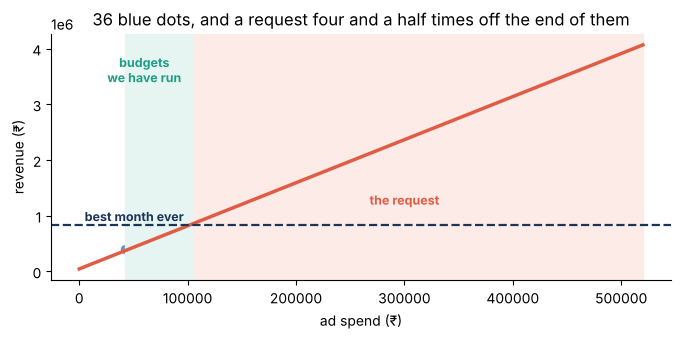

In [39]:
# ---- the picture that makes both points at once ----------------------
g = np.linspace(0, 520000, 60)
plt.plot(g, claim.predict(g.reshape(-1, 1)), color="#E05C45", lw=2.5)
plt.scatter(books.ad_spend, books.revenue, s=55, color="#3E7CB1", alpha=0.8,
            edgecolor="white", lw=0.8)
plt.axvspan(books.ad_spend.min(), books.ad_spend.max(), color="#E6F5F1")
plt.axvspan(books.ad_spend.max(), 520000, color="#FCEBE7")
plt.axhline(books.revenue.max(), color="#1B3558", lw=1.6, ls="--")
plt.text(5000, books.revenue.max()*1.08, "best month ever", fontweight="bold",
         color="#1B3558", fontsize=9)
plt.text(60000, 3.4e6, "budgets\nwe have run", ha="center", color="#1F9E86",
         fontweight="bold", fontsize=9)
plt.text(300000, 1.2e6, "the request", ha="center", color="#E05C45",
         fontweight="bold", fontsize=9)
plt.xlabel("ad spend (₹)"); plt.ylabel("revenue (₹)")
plt.title("36 blue dots, and a request four and a half times off the end of them")
plt.show()

### Reason 1 — the arrow points the other way

Look at `ad_spend ÷ revenue`, month by month:

```
smallest 0.103   largest 0.141   average 0.1192   spread 0.0076
```

**Every single month, the ad budget is about 12% of that month's revenue.** That is not
something that happens by chance across 36 months. It is a **budgeting policy**: the team
sets the budget as a percentage of what they expect to sell.

So the causation runs **revenue → ad spend**, not the other way round. The regression
found a real, strong relationship and then read it backwards.

Then what *does* drive revenue? The answer was sitting in the table the whole time:

```
revenue from the MONTH NUMBER alone : R² = 0.4971
   the company grows ₹8,270 per month, advertising or not
revenue from month + ad_spend       : R² = 0.9332
```

The company is **growing**, steadily, month after month. Revenue goes up. The 12% rule
pushes the ad budget up with it. Both climb together, and a regression of either on the
other looks magnificent.

**This is the mistake from the lecture's number 5**, at full scale. A line measures that
two things move together. It is completely silent about which one moves the other — or
whether a third thing moves both.

### Reason 2 — the request is off the end of the data

```
ad spend has ranged from ₹41,860 to ₹105,880
the request is          ₹500,000
that is 4.7x the largest budget ever run
```

Even if the causation ran the right way, the model has **never seen a budget remotely like
this one**. The projection of ₹3,913,559 is 4.7 times the best month in company history.

And the model is not clever enough to be suspicious about that, because a line will answer
any question you ask it.

### Why these are two *different* mistakes

This matters for the marks. They fail independently:

- **Reason 1** is about **direction**. No amount of extra data fixes it. You would need an
  experiment — deliberately vary the budget *independently of* expected revenue and see
  what happens.
- **Reason 2** is about **range**. More data *would* fix it: run some genuinely large
  budgets and you will learn what they do.

A reply that catches only one of them still signs off a bad decision.

### The reply to the board

> The 0.93 is real but it is pointing backwards. Our own policy sets each month's ad
> budget at roughly 12% of expected revenue — it holds in all 36 months, within half a
> percentage point — so revenue is driving the budget, not the reverse. What is actually
> growing revenue is the business itself: month number alone explains about half the
> variation, at roughly ₹8,300 a month, with no reference to advertising. Separately,
> ₹500,000 is 4.7 times the largest budget we have ever run, so the ₹3.9m projection is
> extrapolation rather than evidence. I would suggest a controlled test instead: pick three
> months, set the budget independently of the forecast, and measure what actually happens.

### The habit to take away

**When a regression tells you something commercially wonderful, ask what else could produce
that same pattern.** Here, two innocent facts — a growing company and a percentage-based
budget — manufacture an R² of 0.93 out of nothing causal at all.

---
## Before you hand it in

- Did you **draw the scatter plot** before fitting anything?
- Can you finish the sentence *"one more unit of X is worth ___ of Y"*?
- Is `x = 0` inside your data? If not, you may not quote the intercept.
- Is every number you predicted **inside the range** you actually observed?
- Did you plot the **errors** against the input, and check for a pattern?
- Did you report R² **against a baseline**, not on its own?
- Did you say "moves with" rather than "causes"?

Four numbers worth carrying away:

- The best line on the five students had total squared error **14**. The exactly
  upside-down line scored **2,574** — and both had errors that added to **zero**.
- The formula and gradient descent both landed on slope **8.000000**. Same bowl, one
  bottom.
- One mistyped row out of 41 cut R² from **0.949 to 0.500**. Least squares squares its
  errors, so one bad point can outweigh forty good ones.
- An R² of **0.93** was produced by a growing company and a percentage-based budget, with
  no causation anywhere in it.

Answers will be shared after class.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*